<a href="https://colab.research.google.com/github/Rush1985-hub/23BME013_CFDLAB/blob/main/03_Centrifugal_Pump_FDM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 3: Centrifugal-pump model using FDM

**Aim:** Study pressure rise, pump head, velocity components, and temperature rise in a simplified rotating annular passage.

**Numerical method:** A steady two-dimensional finite-difference method on a uniform polar grid. The velocity field is prescribed from a reduced-order centrifugal-pump model. Pressure is integrated radially with finite differences. Temperature is solved by assembling a sparse finite-difference linear system with first-order upwind advection and central diffusion.

> **Scope:** This is a teaching model, not a blade-resolved pump CFD solver. It isolates centrifugal pressure rise, rotating-frame velocity, advection, diffusion, wall heat transfer, and finite-difference verification.

Run cells from top to bottom. The quick case checks the workflow; the lab case is the prescribed report case.

## Learning objectives

Students should be able to:

1. State the assumptions and governing equations.
2. Construct a polar FDM grid and identify radial and periodic angular neighbours.
3. Replace derivatives by finite-difference approximations.
4. Explain upwind advection, central diffusion, sparse matrix assembly, and the linear-system residual.
5. Apply Dirichlet, Neumann, and periodic boundary conditions.
6. Interpret residual histories and verification checks.
7. Compare finite-difference pressure integration with a closed-form reference.
8. Separate numerical observations from physical claims outside the model.

## Model, notation, and assumptions

The passage is an annulus with inner radius \(r_1\), outer radius \(r_2\), and depth \(b\). The grid is

\[
r_i=r_1+i\Delta r,\quad \theta_j=j\Delta\theta,\quad
\Delta r=\frac{r_2-r_1}{N_r-1},\quad
\Delta\theta=\frac{2\pi}{N_\theta}.
\]

The prescribed velocities are

\[
u_r=u_{r,1}\frac{r_1}{r},\qquad
u_\theta=s\Omega r,\qquad
w_\theta=u_\theta-\Omega r=(s-1)\Omega r,
\]

where \(\Omega=2\pi\,\mathrm{RPM}/60\), \(s\) is the swirl fraction, and \(w_\theta\) is the relative tangential velocity.

The model does not solve full Navier–Stokes equations, blade loading, turbulence, blade-to-blade interaction, pressure-velocity coupling, or three-dimensional effects.

## Governing equations

The reduced radial momentum model is

\[
\frac{dp}{dr}=\rho\frac{u_\theta^2}{r}-\frac{12\mu u_r}{b^2}.
\]

The first term represents centrifugal pressure rise. The second term is a simple laminar passage-loss model. We set \(p(r_1)=0\), so pressure is gauge pressure.

The rotating-frame thermal equation is

\[
\rho c_p\left(u_r\frac{\partial T}{\partial r}
+\frac{w_\theta}{r}\frac{\partial T}{\partial\theta}\right)
=k\left[\frac{1}{r}\frac{\partial}{\partial r}
\left(r\frac{\partial T}{\partial r}\right)
+\frac{1}{r^2}\frac{\partial^2T}{\partial\theta^2}\right]
+\rho c_p\beta(T_w-T)+S_T,
\]

where \(\alpha=k/(\rho c_p)\), \(\beta=2h_w/(\rho c_p b)\), and \(S_T\) is a small optional loss-heating source expressed as energy per unit volume and time.

## FDM discretization

For pressure, a forward radial finite difference gives

\[
p_{i+1}=p_i+\Delta r\left[
\rho\frac{u_{\theta,i}^2}{r_i}
-\frac{12\mu u_{r,i}}{b^2}\right].
\]

For temperature, use central differences for diffusion:

\[
T_{rr}\approx\frac{E-2T_{i,j}+W}{\Delta r^2},\qquad
T_{\theta\theta}\approx\frac{N-2T_{i,j}+S}{\Delta\theta^2}.
\]

For advection, let \(v_{\theta,\mathrm{rel}}=w_\theta/r_i\) and define

\[
a_W=\frac{\alpha}{\Delta r^2}+\frac{\max(u_r,0)}{\Delta r},\quad
a_E=\frac{\alpha}{\Delta r^2}+\frac{\max(-u_r,0)}{\Delta r},
\]

\[
a_S=\frac{\alpha}{r_i^2\Delta\theta^2}
+\frac{\max(v_{\theta,\mathrm{rel}},0)}{\Delta\theta},\quad
a_N=\frac{\alpha}{r_i^2\Delta\theta^2}
+\frac{\max(-v_{\theta,\mathrm{rel}},0)}{\Delta\theta}.
\]

The pointwise FDM equation can be assembled as (A\mathbf{T}=\mathbf{b}):

\[
T_{i,j}^{*}=
\frac{a_WW+a_EE+a_SS+a_NN+\beta T_w+S_T/(\rho c_p)}
{a_W+a_E+a_S+a_N+\beta}.
\]

The assembled algebraic residual is

\[
R_A=\|A\mathbf{T}-\mathbf{b}\|_\infty.
\]

## Boundary conditions and implementation checks

At the inlet \(r=r_1\), impose the Dirichlet condition

\[
T(r_1,\theta)=T_\mathrm{in}.
\]

At the outlet \(r=r_2\), impose zero radial diffusive flux:

\[
\frac{\partial T}{\partial r}=0.
\]

The code uses the second-order one-sided formula

\[
\frac{3T_N-4T_{N-1}+T_{N-2}}{2\Delta r}=0
\quad\Rightarrow\quad
T_N=\frac{4T_{N-1}-T_{N-2}}{3}.
\]

The angular direction is periodic:

\[
T(r,\theta+2\pi)=T(r,\theta).
\]

The summary reports inlet error, outlet-gradient residual, angular periodicity error, and pressure error against the closed-form reference.

In [1]:
# 1. Runtime helpers
from pathlib import Path
import shutil, subprocess, sys, zipfile
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

IN_COLAB = False
try:
    from google.colab import files as colab_files
    IN_COLAB = True
except ImportError:
    colab_files = None

def run_solver(script_path, args, output_dir, timeout=1800):
    output_dir = Path(output_dir)
    if output_dir.exists():
        shutil.rmtree(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    command = [sys.executable, str(script_path), *[str(v) for v in args]]
    print("Running:", " ".join(command))
    result = subprocess.run(command, cwd=output_dir, capture_output=True, text=True, timeout=timeout)
    (output_dir / "solver_stdout.log").write_text(result.stdout, encoding="utf-8")
    (output_dir / "solver_stderr.log").write_text(result.stderr, encoding="utf-8")
    if result.stdout.strip():
        print(result.stdout.strip())
    if result.returncode:
        raise RuntimeError(result.stderr.strip() or f"Solver exited with code {result.returncode}")
    return output_dir

def read_csv(path):
    return np.atleast_1d(np.genfromtxt(path, delimiter=",", names=True, dtype=None, encoding="utf-8"))

def show_summary(path):
    text = Path(path).read_text(encoding="utf-8").strip()
    display(Markdown("### Solver summary\n\n    " + text.replace("\n", "\n    ")))
    return text

def make_zip(output_dir, number):
    output_dir = Path(output_dir)
    archive = output_dir.parent / f"experiment_{number:02d}_fdm_results.zip"
    if archive.exists():
        archive.unlink()
    with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as z:
        for path in sorted(output_dir.rglob("*")):
            if path.is_file():
                z.write(path, path.relative_to(output_dir))
    print("Results archive:", archive)
    return archive

ROOT = Path("/content/cfd_lab_exp03_fdm") if IN_COLAB else Path.cwd() / "_colab_runtime_exp03_fdm"
CODE_DIR, OUTPUT_DIR = ROOT / "code", ROOT / "outputs"
CODE_DIR.mkdir(parents=True, exist_ok=True)
print("Runtime:", "Google Colab" if IN_COLAB else "local notebook test")
print("Working folder:", ROOT)

Runtime: Google Colab
Working folder: /content/cfd_lab_exp03_fdm


In [2]:
# 2. Write the standalone polar FDM solver
solver_source = r'''from __future__ import annotations
import csv
import math
import sys
import numpy as np
from scipy.sparse import lil_matrix
from scipy.sparse.linalg import spsolve

def main():
    # nr, ntheta, rpm, Re, Tin, Twall, swirl, wall_htc, loss_fraction
    nr = int(sys.argv[1]) if len(sys.argv) > 1 else 80
    ntheta = int(sys.argv[2]) if len(sys.argv) > 2 else 160
    rpm = float(sys.argv[3]) if len(sys.argv) > 3 else 2000.0
    Re = float(sys.argv[4]) if len(sys.argv) > 4 else 500.0
    Tin = float(sys.argv[5]) if len(sys.argv) > 5 else 300.0
    Twall = float(sys.argv[6]) if len(sys.argv) > 6 else 330.0
    swirl = float(sys.argv[7]) if len(sys.argv) > 7 else 0.85
    wall_htc = float(sys.argv[8]) if len(sys.argv) > 8 else 120.0
    loss_fraction = float(sys.argv[9]) if len(sys.argv) > 9 else 0.04

    if nr < 5 or ntheta < 8 or rpm <= 0 or Re <= 0:
        raise ValueError("Use nr>=5, ntheta>=8, and positive RPM/Re")
    if not 0 <= swirl <= 1.5 or wall_htc < 0 or loss_fraction < 0:
        raise ValueError("Check swirl, wall_htc, and loss_fraction")

    r1, r2, b = 0.030, 0.120, 0.010
    rho, mu, cp, k = 997.0, 0.0010, 4180.0, 0.60
    g = 9.81
    Omega = rpm * 2.0 * math.pi / 60.0
    Dh = 2.0 * b
    ur1 = Re * mu / (rho * Dh)

    r = np.linspace(r1, r2, nr)
    theta = np.linspace(0.0, 2.0 * math.pi, ntheta, endpoint=False)
    rr, tt = np.meshgrid(r, theta, indexing="ij")
    dr, dtheta = r[1] - r[0], theta[1] - theta[0]

    ur1d = ur1 * r1 / r
    utheta1d = swirl * Omega * r
    wtheta1d = utheta1d - Omega * r
    ur = ur1d[:, None] * np.ones((1, ntheta))
    utheta = utheta1d[:, None] * np.ones((1, ntheta))
    wtheta = wtheta1d[:, None] * np.ones((1, ntheta))
    uabs_x = ur*np.cos(tt) - utheta*np.sin(tt)
    uabs_y = ur*np.sin(tt) + utheta*np.cos(tt)
    urel_x = ur*np.cos(tt) - wtheta*np.sin(tt)
    urel_y = ur*np.sin(tt) + wtheta*np.cos(tt)

    # Radial pressure FDM and closed-form verification solution.
    pressure = np.zeros(nr)
    rhs_p = rho*utheta1d**2/r - 12.0*mu*ur1d/b**2
    pressure[1:] = np.cumsum(dr * rhs_p[:-1])
    pressure_exact = (0.5*rho*swirl**2*Omega**2*(r**2-r1**2)
                      - 12.0*mu*ur1*r1*np.log(r/r1)/b**2)

    alpha = k/(rho*cp)
    beta = 2.0*wall_htc/(rho*cp*b)
    source_rate = loss_fraction*np.abs(ur1d)*(Omega*r)**2/(b*cp)

    # Assemble every FDM equation into A*T=b. The first and last radial
    # rows contain the Dirichlet and Neumann boundary equations.
    n_unknowns = nr * ntheta
    A = lil_matrix((n_unknowns, n_unknowns), dtype=float)
    rhs_T = np.zeros(n_unknowns)
    def index(i, j):
        return i*ntheta + j

    for j in range(ntheta):
        row_in = index(0, j)
        A[row_in, row_in] = 1.0
        rhs_T[row_in] = Tin
        row_out = index(nr-1, j)
        A[row_out, index(nr-1, j)] = 3.0
        A[row_out, index(nr-2, j)] = -4.0
        A[row_out, index(nr-3, j)] = 1.0

    for i in range(1, nr-1):
        ri = r[i]
        ar, at = alpha/dr**2, alpha/(ri**2*dtheta**2)
        vr, va = ur1d[i], wtheta1d[i]/ri
        aw = ar + max(vr, 0.0)/dr
        ae = ar + max(-vr, 0.0)/dr
        ass = at + max(va, 0.0)/dtheta
        an = at + max(-va, 0.0)/dtheta
        ap = aw + ae + ass + an + beta
        for j in range(ntheta):
            row = index(i, j)
            A[row, row] = ap
            A[row, index(i-1, j)] = -aw
            A[row, index(i+1, j)] = -ae
            A[row, index(i, (j-1) % ntheta)] = -ass
            A[row, index(i, (j+1) % ntheta)] = -an
            rhs_T[row] = beta*Twall + source_rate[i]

    A = A.tocsr()
    T = spsolve(A, rhs_T).reshape(nr, ntheta)
    if not np.all(np.isfinite(T)):
        raise FloatingPointError("The FDM linear solve returned a non-finite field")
    linear_residual = float(np.max(np.abs(A @ T.ravel() - rhs_T)))
    history = [[1, linear_residual, T.min(), T.max(), T[-1, :].mean()]]
    print(f"sparse FDM solve residual={linear_residual:.6e} outlet_temperature={history[-1][4]:.6f}")

    pressure_error = float(np.max(np.abs(pressure-pressure_exact)))
    periodic_error = float(np.max(np.abs(T[:, 0]-T[:, -1])))
    outlet_gradient = float(np.max(np.abs((3*T[-1, :]-4*T[-2, :]+T[-3, :])/(2*dr))))
    mass_flow = rho*ur1*(2*math.pi*r1*b)
    pump_head = float((pressure[-1]-pressure[0])/(rho*g))
    heat_gain = float(mass_flow*cp*(T[-1, :].mean()-Tin))

    np.savez("pump_fdm_fields.npz", r=np.repeat(r[:, None], ntheta, axis=1),
             theta=np.repeat(theta[None, :], nr, axis=0), temperature=T,
             pressure=pressure, pressure_exact=pressure_exact,
             u_abs_x=uabs_x, u_abs_y=uabs_y, u_rel_x=urel_x, u_rel_y=urel_y)
    with open("pump_fdm_history.csv", "w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(["iteration","residual_linf","minimum_temperature",
                         "maximum_temperature","outlet_temperature"])
        writer.writerows(history)
    with open("pump_fdm_summary.txt", "w", encoding="utf-8") as f:
        f.write("Centrifugal-pump annular passage solved with polar FDM\n")
        f.write(f"grid_nr {nr}\ngrid_ntheta {ntheta}\ndr_m {dr:.12e}\ndtheta_rad {dtheta:.12e}\n")
        f.write(f"rpm {rpm:.12g}\nomega_rad_per_s {Omega:.12e}\nRe {Re:.12g}\nswirl_fraction {swirl:.12g}\n")
        f.write(f"r1_m {r1:.12e}\nr2_m {r2:.12e}\npassage_depth_m {b:.12e}\n")
        f.write(f"Tin_K {Tin:.12e}\nTwall_K {Twall:.12e}\nTout_K {T[-1, :].mean():.12e}\n")
        f.write(f"pressure_rise_Pa {pressure[-1]-pressure[0]:.12e}\npump_head_m {pump_head:.12e}\n")
        f.write(f"mass_flow_rate_kg_per_s {mass_flow:.12e}\nfluid_heat_gain_W {heat_gain:.12e}\n")
        f.write(f"linear_system_residual_linf {history[-1][1]:.12e}\n")
        f.write(f"max_pressure_fd_vs_exact_error_Pa {pressure_error:.12e}\n")
        f.write(f"periodic_temperature_check_K {periodic_error:.12e}\n")
        f.write(f"outlet_neumann_check_K_per_m {outlet_gradient:.12e}\n")
        f.write("discretization pressure_forward_fd; advection_upwind_fd; diffusion_central_fd; sparse_direct_fdm\n")
        f.write("model_scope teaching_level_reduced_order_srf_not_blade_resolved_cfd\n")
    print("Wrote pump_fdm_fields.npz, pump_fdm_history.csv, and pump_fdm_summary.txt")

if __name__ == "__main__":
    raise SystemExit(main())
'''
SCRIPT = CODE_DIR / "fdm_centrifugal_pump.py"
SCRIPT.write_text(solver_source, encoding="utf-8")
print("Finite-difference solver written to:", SCRIPT)

Finite-difference solver written to: /content/cfd_lab_exp03_fdm/code/fdm_centrifugal_pump.py


## Parameters

Use quick to verify the workflow, lab for the prescribed case, and custom for controlled studies. The Reynolds number defines inlet speed through \(Re=\rho u_{r,1}D_h/\mu\); it is a control parameter here, not a complete similarity description of a real pump.

In [3]:
# 3. Select run mode and parameters
RUN_MODE = "custom"  #@param ["quick", "lab", "custom"]

nr = 80  #@param {type:"integer"}
ntheta = 160  #@param {type:"integer"}
rpm = 3000.0  #@param {type:"number"}
Re = 500.0  #@param {type:"number"}
T_in = 300.0  #@param {type:"number"}
T_wall = 330.0  #@param {type:"number"}
swirl = 0.85  #@param {type:"number"}
wall_HTC = 120.0  #@param {type:"number"}
loss_fraction = 0.04  #@param {type:"number"}

QUICK_ARGS = [20, 32, 1500, 300, 300, 330, 0.8, 100, 0.04]
LAB_ARGS = [80, 160, 2000, 500, 300, 330, 0.85, 120, 0.04]
CUSTOM_ARGS = [nr, ntheta, rpm, Re, T_in, T_wall, swirl, wall_HTC, loss_fraction]
ARGS = QUICK_ARGS if RUN_MODE == "quick" else LAB_ARGS if RUN_MODE == "lab" else CUSTOM_ARGS
print("Run mode:", RUN_MODE)
print("Arguments:", ARGS)

Run mode: custom
Arguments: [80, 160, 3000.0, 500.0, 300.0, 330.0, 0.85, 120.0, 0.04]


In [4]:
# 4. Run the finite-difference solver
OUT = run_solver(SCRIPT, ARGS, OUTPUT_DIR)

Running: /usr/bin/python3 /content/cfd_lab_exp03_fdm/code/fdm_centrifugal_pump.py 80 160 3000.0 500.0 300.0 330.0 0.85 120.0 0.04
sparse FDM solve residual=6.302310e-10 outlet_temperature=301.553360
Wrote pump_fdm_fields.npz, pump_fdm_history.csv, and pump_fdm_summary.txt


## Summary and linear-system residual

Read the summary first. The sparse direct solve should produce a small algebraic residual. That residual alone does not establish physical correctness; also check the temperature range, boundary diagnostics, grid, and pressure comparison.

In [5]:
# 5. Read the summary and plot the algebraic residual
summary = show_summary(OUT / "pump_fdm_summary.txt")
history = read_csv(OUT / "pump_fdm_history.csv")
print(f"linear-system residual: {history['residual_linf'][0]:.6e}")
print(f"outlet temperature: {history['outlet_temperature'][0]:.6f} K")

### Solver summary

    Centrifugal-pump annular passage solved with polar FDM
    grid_nr 80
    grid_ntheta 160
    dr_m 1.139240506329e-03
    dtheta_rad 3.926990816987e-02
    rpm 3000
    omega_rad_per_s 3.141592653590e+02
    Re 500
    swirl_fraction 0.85
    r1_m 3.000000000000e-02
    r2_m 1.200000000000e-01
    passage_depth_m 1.000000000000e-02
    Tin_K 3.000000000000e+02
    Twall_K 3.300000000000e+02
    Tout_K 3.015533603804e+02
    pressure_rise_Pa 4.762394676183e+05
    pump_head_m 4.869240418690e+01
    mass_flow_rate_kg_per_s 4.712388980385e-02
    fluid_heat_gain_W 3.059776025747e+02
    linear_system_residual_linf 6.302309785156e-10
    max_pressure_fd_vs_exact_error_Pa 3.644692066507e+03
    periodic_temperature_check_K 2.842170943040e-13
    outlet_neumann_check_K_per_m 7.484383483340e-11
    discretization pressure_forward_fd; advection_upwind_fd; diffusion_central_fd; sparse_direct_fdm
    model_scope teaching_level_reduced_order_srf_not_blade_resolved_cfd

linear-system residual: 6.302310e-10
outlet temperature: 301.553360 K


## Field plots

The data are stored on a polar grid and plotted in physical \(x\)-\(y\) coordinates. The vectors show the prescribed relative velocity used in the rotating-frame energy equation.

/tmp/ipykernel_3232/1601522994.py:9: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  im = axes[0].pcolormesh(x_field, y_field, temperature, shading="auto", cmap="inferno")
/tmp/ipykernel_3232/1601522994.py:22: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  axes[2].pcolormesh(x_field, y_field, speed, shading="auto", cmap="viridis")


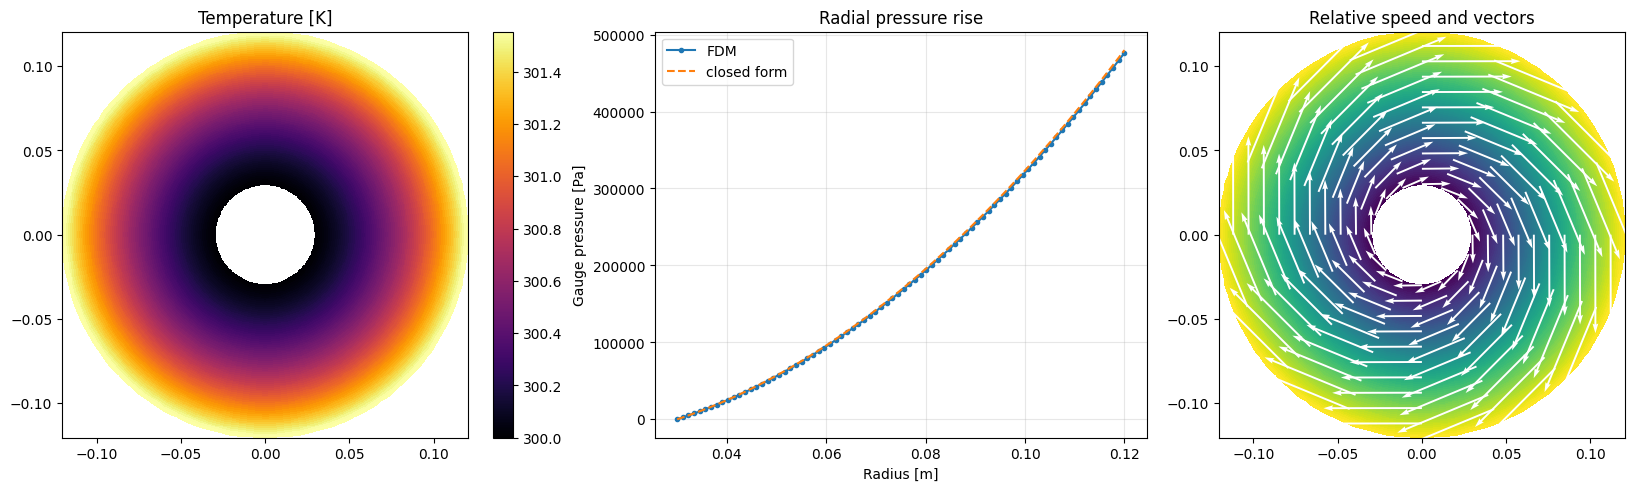

In [6]:
# 6. Plot temperature, pressure, and relative velocity
fields = np.load(OUT / "pump_fdm_fields.npz")
r_field, theta_field = fields["r"], fields["theta"]
x_field, y_field = r_field*np.cos(theta_field), r_field*np.sin(theta_field)
temperature, pressure = fields["temperature"], fields["pressure"]
ux, uy = fields["u_rel_x"], fields["u_rel_y"]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), constrained_layout=True)
im = axes[0].pcolormesh(x_field, y_field, temperature, shading="auto", cmap="inferno")
axes[0].set_title("Temperature [K]")
axes[0].set_aspect("equal")
fig.colorbar(im, ax=axes[0])

axes[1].plot(r_field[:, 0], pressure, "o-", ms=3, label="FDM")
axes[1].plot(r_field[:, 0], fields["pressure_exact"], "--", label="closed form")
axes[1].set(xlabel="Radius [m]", ylabel="Gauge pressure [Pa]", title="Radial pressure rise")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

skip_r, skip_t = max(1, r_field.shape[0]//10), max(1, r_field.shape[1]//16)
speed = np.sqrt(ux**2 + uy**2)
axes[2].pcolormesh(x_field, y_field, speed, shading="auto", cmap="viridis")
axes[2].quiver(x_field[::skip_r, ::skip_t], y_field[::skip_r, ::skip_t],
               ux[::skip_r, ::skip_t], uy[::skip_r, ::skip_t], color="white", scale=20)
axes[2].set_title("Relative speed and vectors")
axes[2].set_aspect("equal")
plt.show()

## Verification checks

These checks test internal consistency, not real-pump fidelity:

* pressure FDM versus the closed-form solution of the same reduced equation;
* inlet Dirichlet error;
* outlet Neumann residual;
* angular periodicity error;
* temperature range and algebraic residual.

In [7]:
# 7. Print verification diagnostics
dr_value = float(r_field[1, 0] - r_field[0, 0])
inlet_error = float(np.max(np.abs(temperature[0, :] - T_in)))
outlet_gradient = float(np.max(np.abs((3*temperature[-1, :] - 4*temperature[-2, :] + temperature[-3, :])/(2*dr_value))))
periodic_error = float(np.max(np.abs(temperature[:, 0] - temperature[:, -1])))
pressure_error = float(np.max(np.abs(pressure - fields["pressure_exact"])))
print(f"maximum inlet Dirichlet error     : {inlet_error:.6e} K")
print(f"maximum outlet Neumann residual   : {outlet_gradient:.6e} K/m")
print(f"maximum angular periodicity error : {periodic_error:.6e} K")
print(f"maximum pressure FD error         : {pressure_error:.6e} Pa")
print(f"temperature range                 : {temperature.min():.6f} to {temperature.max():.6f} K")

maximum inlet Dirichlet error     : 0.000000e+00 K
maximum outlet Neumann residual   : 7.484383e-11 K/m
maximum angular periodicity error : 2.842171e-13 K
maximum pressure FD error         : 3.644692e+03 Pa
temperature range                 : 300.000000 to 301.553360 K


## Student investigations

**A. RPM scaling:** Run 1000, 2000, and 3000 RPM at fixed Reynolds number and swirl fraction. Plot pump head against RPM squared. Explain the approximately linear relationship and the role of the loss term.

**B. Grid refinement:** Compare \((N_r,N_\theta)=(40,80)\), \((80,160)\), and \((160,320)\). Report pump head, outlet temperature, residual, and pressure error. Discuss grid independence.

**C. Thermal parameters:** Change one at a time: wall temperature, wall heat-transfer coefficient, swirl fraction, and loss fraction. Identify which outputs change and explain why.

**D. Numerical method:** Compare first-order upwind advection with a central-difference advection implementation as an extension. Discuss boundedness, oscillations, and the first-order accuracy of upwind advection. Report how the sparse linear-system residual changes with grid size.

## Report checklist

Include assumptions, parameter table, governing equations, FDM derivation, grid definition, boundary conditions, numerical settings, linear-system residual, labelled fields, pump head, pressure rise, outlet temperature, verification checks, one parameter study, and model limitations.

Use SI units. Label all axes and colour bars. State clearly that pressure is gauge pressure and that this model is not blade-resolved CFD.

## Download results

The archive contains the summary, residual diagnostic, field data, and solver logs. The NPZ field file can be reopened with NumPy.

In [8]:
# 8. Package results
DOWNLOAD_RESULTS = True  #@param {type:"boolean"}
RESULTS_ZIP = make_zip(OUTPUT_DIR, 3)
if DOWNLOAD_RESULTS and IN_COLAB:
    colab_files.download(str(RESULTS_ZIP))
else:
    print("Set DOWNLOAD_RESULTS to True in Colab when ready to download.")
print(sorted(path.name for path in OUTPUT_DIR.iterdir()))

Results archive: /content/cfd_lab_exp03_fdm/experiment_03_fdm_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

['pump_fdm_fields.npz', 'pump_fdm_history.csv', 'pump_fdm_summary.txt', 'solver_stderr.log', 'solver_stdout.log']
